In [1]:
import pickle
import os

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from dataset.dataset import load_data
from dataset.utils import *
import matplotlib.pyplot as plt

torch.set_printoptions(sci_mode=False)

from PIL import Image

# Single playing card dataset

In [2]:
# single playing card dataset has 17 concepts
# multi card dataset has 52 concepts


N_CONCEPT = 17
N_CLASSES = 52
val_loader = load_data("./dataset/playing_cards/train.pkl", 16, dataset_root="./dataset/playing_cards", has_class=True, return_orig=True, shuffle=True)

concept_index_to_string = IndexToString("./dataset/playing_cards/attributes.txt")
class_index_to_string = IndexToString("./dataset/playing_cards/classes.txt")



## Show true concepts and classification + predicted concepts and classification

Image size (channels, width, height): torch.Size([3, 299, 299])
Image concepts: tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 1., 0., 0.])
Image class: 10_Diamonds
original image


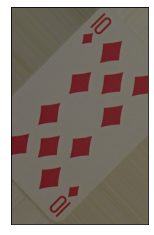

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


transformed image


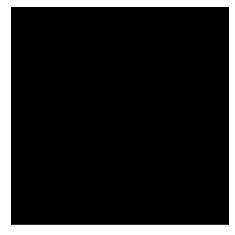

In [3]:
imageId = 0

images, labels, concepts, original_imgs = next(iter(val_loader))
image, label = images[imageId], labels[imageId]

# print / show input
print("Image size (channels, width, height):", image.size())
print("Image concepts:", concepts[imageId])
print("Image class:", class_index_to_string(label.item()))

print("original image")

plt.xticks([])
plt.yticks([])
plt.imshow(original_imgs[imageId].squeeze().permute(1, 2, 0))
plt.show()

print("transformed image")

plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

# Multi playing card dataset

In [4]:

N_CONCEPT = 52
N_CLASSES = 6
val_loader = load_data("./dataset/three_card_poker/train.pkl", 16, dataset_root="./dataset/three_card_poker", has_class=False, return_orig=True, shuffle=True)


concept_index_to_string = IndexToString("./dataset/three_card_poker/concepts.txt")
class_index_to_string = IndexToString("./dataset/three_card_poker/classes.txt")

Image size (channels, width, height): torch.Size([3, 299, 299])
Image concepts: tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        1., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])
Image class: straight_flush
original image


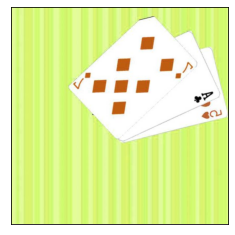

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


transformed image


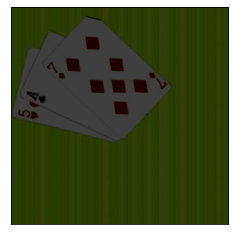

In [5]:
imageId = 0

images, labels, concepts, original_imgs = next(iter(val_loader))
image, label = images[imageId], labels[imageId]

# print / show input
print("Image size (channels, width, height):", image.size())
print("Image concepts:", concepts[imageId])
print("Image class:", class_index_to_string(label.item()))

print("original image")

plt.xticks([])
plt.yticks([])
plt.imshow(original_imgs[imageId].squeeze().permute(1, 2, 0))
plt.show()

print("transformed image")

plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

# Multi image dataset

In [6]:
N_CONCEPT = 52
N_CLASSES = 6

val_loader = load_data("./dataset/individual_three_card_poker/train.pkl", 16, dataset_root="./dataset/individual_three_card_poker", return_orig=True, shuffle=True, multi_image=True)


card_class_index_to_string = IndexToString("./dataset/individual_three_card_poker/card_classes.txt")
card_concept_index_to_string = IndexToString("./dataset/individual_three_card_poker/card_concepts.txt")
hand_class_index_to_string = IndexToString("./dataset/individual_three_card_poker/hand_classes.txt")

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Image size (channels, width, height): torch.Size([3, 3, 299, 299])
Image card classes: tensor([10, 28, 30])
Hand rank class: pair
original image


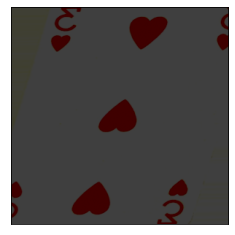

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


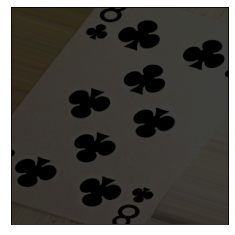

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


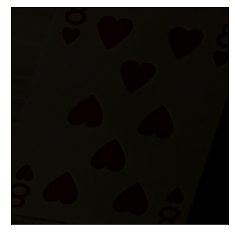

transformed image


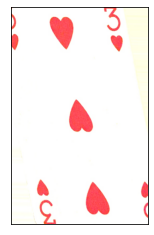

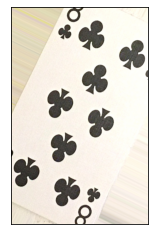

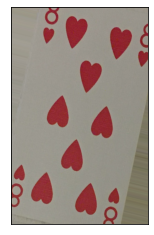

In [9]:
imageId = 0

images, labels, concepts, original_imgs = next(iter(val_loader))

# print / show input
print("Image size (channels, width, height):", images[imageId].size())
print("Image card classes:", concepts[imageId])
print("Hand rank class:", hand_class_index_to_string(labels[imageId].item()))

print("original image")

for image in images[imageId]:

    plt.xticks([])
    plt.yticks([])
    plt.imshow(image.squeeze().permute(1, 2, 0))
    plt.show()

print("transformed image")

for image in original_imgs[imageId]:

    plt.xticks([])
    plt.yticks([])
    plt.imshow(image.squeeze().permute(1, 2, 0))
    plt.show()